# RiMEA 10: Route Allocation

This notebook uses the exported scenario archive [`scenario_files/Rimea-10.zip`](scenario_files/Rimea-10.zip) directly. The room-to-exit allocation is already encoded in the scenario journeys: rooms `1, 2, 3, 4, 7, 8, 9, 10` are assigned to the main exit, and the remaining rooms are assigned to the secondary exit.

The goal is to verify that every simulated person reaches the exit assigned by the scenario.


In [1]:
from datetime import datetime
print(f"Executed on {datetime.now().astimezone().strftime('%d %B %Y, %H:%M %Z')}")

Executed on 15 October 2026, 17:32 CEST


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pedpy
from shapely.geometry import Point, Polygon

from jupedsim_scenarios import load_scenario, run_scenario


In [3]:
plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.facecolor": "#f7f7f5",
        "axes.edgecolor": "#3a3a3a",
        "axes.labelcolor": "#1d1d1d",
        "axes.titleweight": "bold",
        "font.size": 11,
    }
)

EXIT_COLORS = {
    "jps-exits_0": "#2563EB",
    "jps-exits_1": "#D97706",
}


In [4]:
import numpy as np

# House style for the V&V figures (plain matplotlib; applied per figure via rc_context).
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, PathPatch
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.path import Path as MplPath

VV_BLUE, VV_ORANGE, VV_RED, VV_GREEN = "#0072B2", "#E69F00", "#D55E00", "#009E73"
VV_RC = {
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 150,
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "lightgrey", "axes.labelcolor": "dimgrey",
    "axes.titlecolor": "#333333", "axes.titleweight": "normal", "axes.titlesize": 11,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": "dimgrey", "ytick.color": "dimgrey",
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": True, "legend.facecolor": "white", "legend.framealpha": 0.8,
    "legend.edgecolor": "lightgrey", "legend.labelcolor": "dimgrey", "legend.fontsize": 9,
}


def vv_polygon_patch(geom, **kwargs):
    """Matplotlib patch for a shapely (Multi)Polygon, holes included."""
    verts, codes = [], []
    for part in getattr(geom, "geoms", [geom]):
        for ring in [part.exterior, *part.interiors]:
            xy = np.asarray(ring.coords)
            verts.extend(xy)
            codes += [MplPath.MOVETO] + [MplPath.LINETO] * (len(xy) - 2) + [MplPath.CLOSEPOLY]
    return PathPatch(MplPath(verts, codes), **kwargs)


def vv_draw_scenario(ax, scenario, starts=True, pad=0.04):
    """Draw walkable area, exits and start areas of a loaded scenario; return legend handles."""
    ax.add_patch(vv_polygon_patch(scenario.walkable_polygon, facecolor="#eeeeee",
                                  edgecolor="dimgrey", linewidth=1.4, zorder=1))
    handles = [Patch(facecolor="#eeeeee", edgecolor="dimgrey", label="walkable area")]
    if starts:
        for dist in scenario.distributions.values():
            ax.add_patch(MplPolygon(dist["coordinates"], closed=True,
                                    facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                                    linestyle="--", linewidth=1.2, hatch="..", zorder=2))
        handles.append(Patch(facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                             linestyle="--", hatch="..", label="start area"))
    for ex in scenario.exits.values():
        ax.add_patch(MplPolygon(ex["coordinates"], closed=True,
                                facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                                linewidth=1.2, hatch="///", zorder=3))
    if scenario.exits:
        handles.append(Patch(facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                             hatch="///", label="exit"))
    minx, miny, maxx, maxy = scenario.walkable_polygon.bounds
    m = pad * max(maxx - minx, maxy - miny)
    ax.set_xlim(minx - m, maxx + m)
    ax.set_ylim(miny - m, maxy + m)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    return handles


def vv_agent_count(scenario):
    """Total number of agents placed by the scenario's start areas."""
    return sum(int(d.get("parameters", {}).get("number", 0)) for d in scenario.distributions.values())

## Load the Scenario and the Encoded Route Allocation


In [5]:
SCENARIO_ZIP = Path("scenario_files") / "Rimea-10.zip"

scenario = load_scenario(str(SCENARIO_ZIP))
print(scenario.summary())

# Each distribution is linked to a journey via ``journey_weights``; each
# journey's ``sequence`` ends at its assigned exit. Build the
# distribution -> exit allocation encoded in the scenario.
journeys = {j["id"]: j for j in scenario.raw["journeys_v2"]}
journey_map = {
    dist_id: journeys[dist["journey_weights"][0]["journey_id"]]["sequence"][-1]
    for dist_id, dist in scenario.raw["distributions"].items()
}
journey_map


Scenario: scenario_files/Rimea-10.zip
  Model:         CollisionFreeSpeedModel
  Seed:          420
  Max time:      300s
  Exits:         2
  Distributions: 12
  Stages:        0
  Zones:         0
  Journeys:      0
  Agents:        ~23
    jps-distributions_0: 2 agents
    jps-distributions_1: 2 agents
    jps-distributions_2: 2 agents
    jps-distributions_3: 2 agents
    jps-distributions_4: 2 agents
    jps-distributions_5: 2 agents
    jps-distributions_6: 2 agents
    jps-distributions_7: 1 agents
    jps-distributions_8: 2 agents
    jps-distributions_9: 2 agents
    jps-distributions_10: 2 agents
    jps-distributions_11: 2 agents


{'jps-distributions_0': 'jps-exits_0',
 'jps-distributions_1': 'jps-exits_0',
 'jps-distributions_2': 'jps-exits_0',
 'jps-distributions_3': 'jps-exits_0',
 'jps-distributions_4': 'jps-exits_0',
 'jps-distributions_5': 'jps-exits_0',
 'jps-distributions_6': 'jps-exits_0',
 'jps-distributions_7': 'jps-exits_0',
 'jps-distributions_8': 'jps-exits_1',
 'jps-distributions_9': 'jps-exits_1',
 'jps-distributions_10': 'jps-exits_1',
 'jps-distributions_11': 'jps-exits_1'}

## Scenario figure

Rooms and exits from the loaded scenario; each room is coloured by the exit its journey assigns.

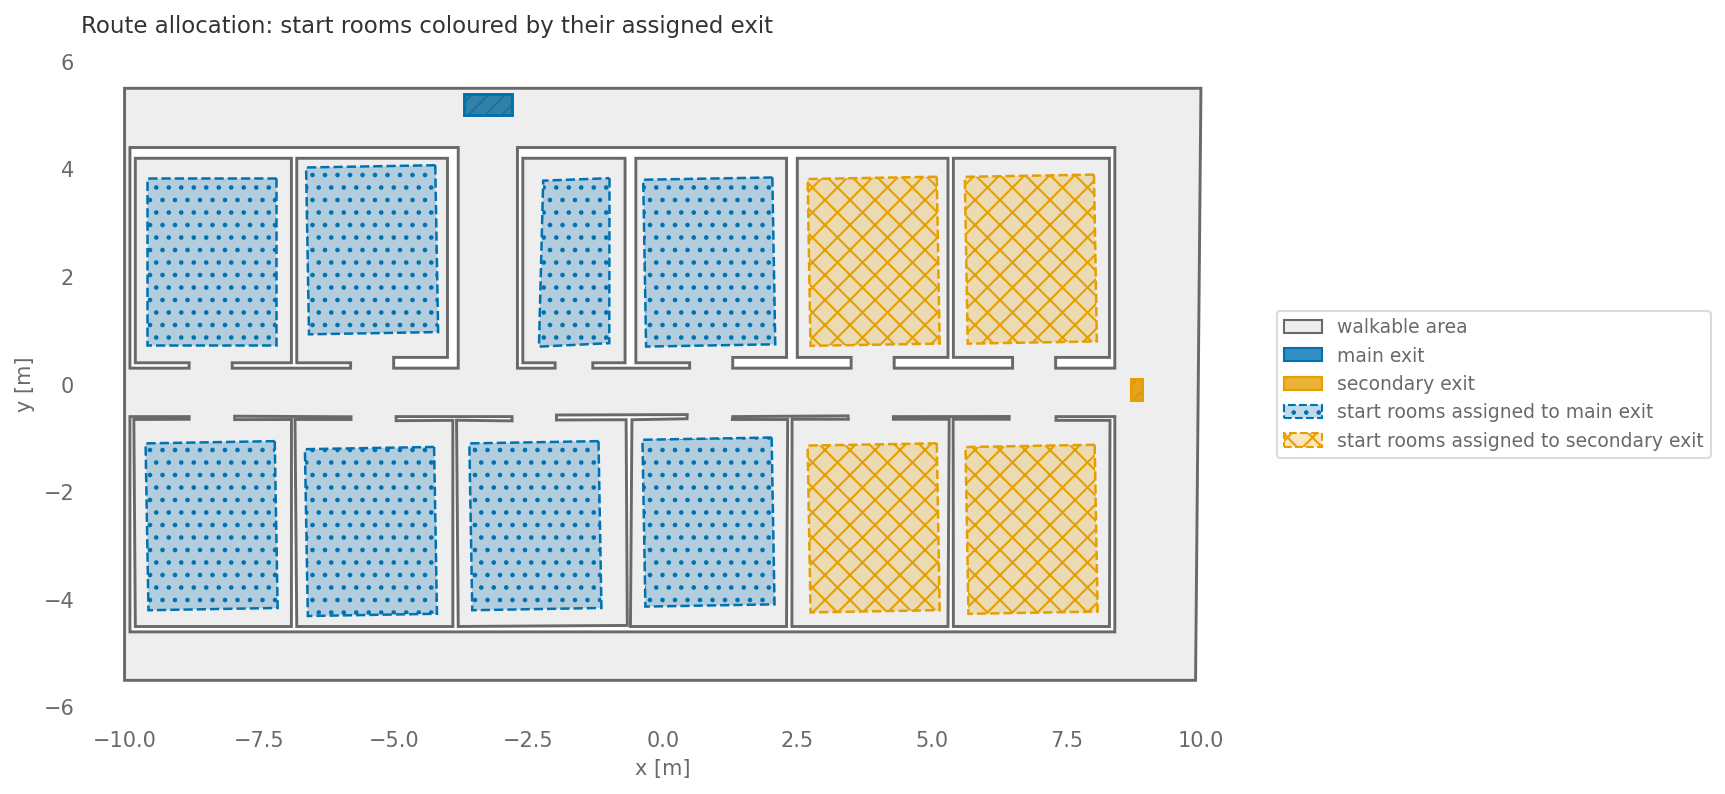

In [6]:
# Start areas coloured by the exit that the scenario journey assigns to them.
exit_ids = sorted(scenario.exits)
palette = dict(zip(exit_ids, [VV_BLUE, VV_ORANGE]))
hatches = dict(zip(exit_ids, ["..", "xx"]))
names = {"jps-exits_0": "main exit", "jps-exits_1": "secondary exit"}
with plt.rc_context(VV_RC):
    fig, ax = plt.subplots(figsize=(10, 6))
    handles = vv_draw_scenario(ax, scenario, starts=False)
    handles = handles[:1]
    for dist_id, dist in scenario.distributions.items():
        target = journey_map[dist_id]
        ax.add_patch(MplPolygon(dist["coordinates"], closed=True, facecolor=to_rgba(palette[target], 0.25),
                                edgecolor=palette[target], linestyle="--", linewidth=1.2,
                                hatch=hatches[target], zorder=2))
    for ex_id, ex in scenario.exits.items():
        ax.add_patch(MplPolygon(ex["coordinates"], closed=True, facecolor=to_rgba(palette.get(ex_id, VV_RED), 0.8),
                                edgecolor=palette.get(ex_id, VV_RED), linewidth=1.4, zorder=3))
    for t in exit_ids:
        handles.append(Patch(facecolor=to_rgba(palette[t], 0.8), edgecolor=palette[t], label=names.get(t, t)))
    for t in sorted(set(journey_map.values())):
        handles.append(Patch(facecolor=to_rgba(palette[t], 0.25), edgecolor=palette[t], linestyle="--",
                             hatch=hatches[t], label=f"start rooms assigned to {names.get(t, t)}"))
    ax.set_title("Route allocation: start rooms coloured by their assigned exit", loc="left")
    ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.02, 0.5))
    plt.show()

## Helper Functions

We identify each agent by its initial room polygon, then compare the assigned exit from the scenario journey with the exit closest to the agent's final recorded position.


In [7]:
def agent_to_distribution(trajectory, distributions):
    first_positions = trajectory.data.sort_values(["id", "frame"]).groupby("id").first().reset_index()
    distribution_polygons = {key: Polygon(value["coordinates"]) for key, value in distributions.items()}
    mapping = {}
    for row in first_positions.itertuples():
        point = Point(row.x, row.y)
        for distribution_id, polygon in distribution_polygons.items():
            if polygon.covers(point):
                mapping[row.id] = distribution_id
                break
    return mapping


def agent_to_actual_exit(trajectory, exits):
    last_positions = trajectory.data.sort_values(["id", "frame"]).groupby("id").last().reset_index()
    exit_polygons = {key: Polygon(value["coordinates"]) for key, value in exits.items()}
    mapping = {}
    for row in last_positions.itertuples():
        point = Point(row.x, row.y)
        mapping[row.id] = min(
            exit_polygons,
            key=lambda exit_id: exit_polygons[exit_id].distance(point),
        )
    return mapping


def exit_measurement_lines(exits):
    lines = []
    for exit_id, exit_def in exits.items():
        coords = exit_def["coordinates"][:-1]
        xs = [xy[0] for xy in coords]
        ys = [xy[1] for xy in coords]
        if (max(xs) - min(xs)) >= (max(ys) - min(ys)):
            x = max(xs)
            lines.append((exit_id, pedpy.MeasurementLine([(x, min(ys)), (x, max(ys))])))
        else:
            y = max(ys)
            lines.append((exit_id, pedpy.MeasurementLine([(min(xs), y), (max(xs), y)])))
    return lines


## Run the Scenario


In [8]:
%%capture
result = run_scenario(scenario, seed=42)
trajectory = pedpy.TrajectoryData(
    result.trajectory_dataframe()[["id", "frame", "x", "y"]].copy(),
    frame_rate=result.frame_rate,
)
walkable_area = pedpy.WalkableArea(scenario.walkable_polygon)

agent_distribution = agent_to_distribution(trajectory, scenario.raw["distributions"])
expected_exit = {agent_id: journey_map[distribution_id] for agent_id, distribution_id in agent_distribution.items()}
actual_exit = agent_to_actual_exit(trajectory, scenario.raw["exits"])
assignment_rows = [
    {
        "agent_id": agent_id,
        "distribution": agent_distribution[agent_id],
        "expected_exit": expected_exit[agent_id],
        "actual_exit": actual_exit[agent_id],
        "matches": expected_exit[agent_id] == actual_exit[agent_id],
    }
    for agent_id in sorted(expected_exit)
]


## Plot the Allocated Trajectories

Blue trajectories are assigned to the main exit, orange trajectories to the secondary exit. The white measurement lines mark the exit regions.


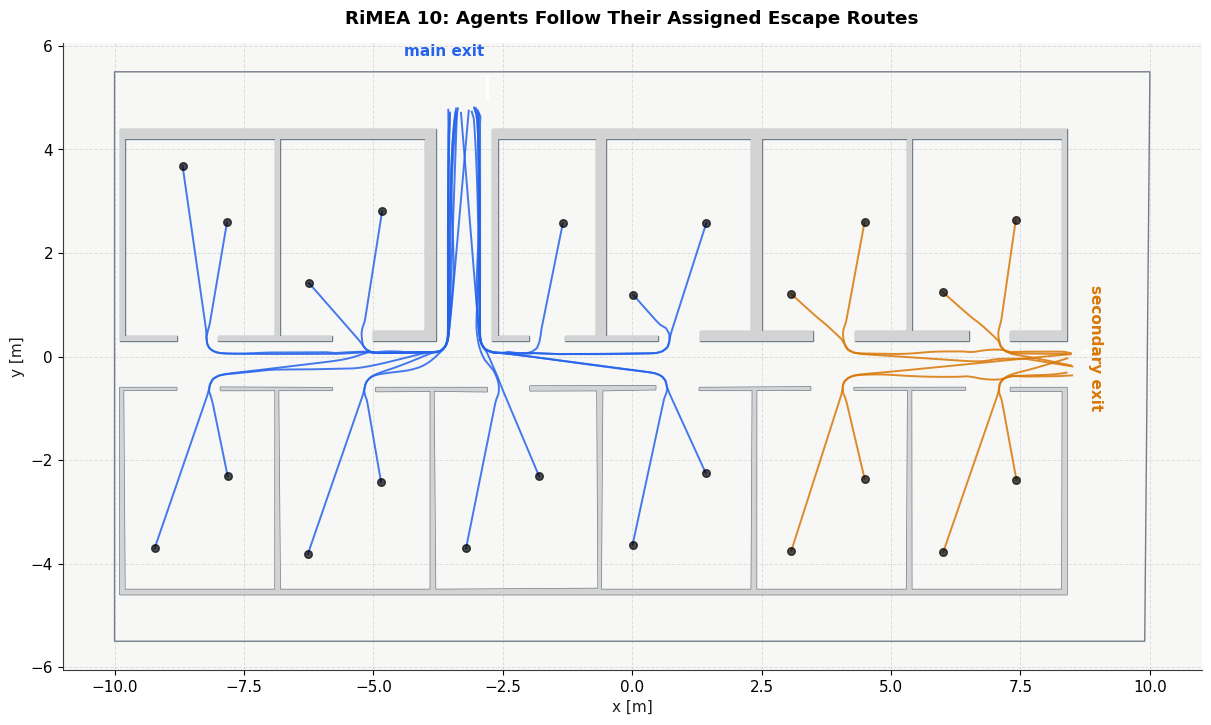

In [9]:
exit_lines = exit_measurement_lines(scenario.raw["exits"])

fig, ax = plt.subplots(figsize=(12, 7), constrained_layout=True)
pedpy.plot_measurement_setup(
    walkable_area=walkable_area,
    measurement_lines=[line for _, line in exit_lines],
    axes=ax,
    ml_width=2.5,
    ml_alpha=0.7,
    ml_color="white",
).set_aspect("equal")

for exit_id in ["jps-exits_0", "jps-exits_1"]:
    agent_ids = [agent_id for agent_id, assigned_exit in expected_exit.items() if assigned_exit == exit_id]
    for agent_id in agent_ids:
        agent_traj = trajectory.data[trajectory.data["id"] == agent_id]
        ax.plot(
            agent_traj["x"],
            agent_traj["y"], 
            color=EXIT_COLORS[exit_id],
            linewidth=1.4,
            alpha=0.85,       
        )
first_frame = trajectory.data["frame"].min()
first_frame_data = trajectory.data[trajectory.data["frame"] == first_frame]
ax.scatter(first_frame_data["x"], first_frame_data["y"], 
          color="black", marker="o", s=30, alpha=0.7, zorder=5, label=f"Frame {first_frame}")

ax.text(-4.4, 5.8, "main exit", color=EXIT_COLORS["jps-exits_0"], fontsize=11, weight="bold")
ax.text(8.8, -1, "secondary exit", color=EXIT_COLORS["jps-exits_1"], fontsize=11, weight="bold", rotation=-90)
ax.set_title("RiMEA 10: Agents Follow Their Assigned Escape Routes", pad=14)
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.grid(True, linestyle="--", linewidth=0.7, alpha=0.35)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()


## Verify the Allocation


In [10]:
import pandas as pd
df = pd.DataFrame(assignment_rows)
print(df.to_string(index=False))

 agent_id         distribution expected_exit actual_exit  matches
        1  jps-distributions_0   jps-exits_0 jps-exits_0     True
        2  jps-distributions_0   jps-exits_0 jps-exits_0     True
        3  jps-distributions_1   jps-exits_0 jps-exits_0     True
        4  jps-distributions_1   jps-exits_0 jps-exits_0     True
        5  jps-distributions_2   jps-exits_0 jps-exits_0     True
        6  jps-distributions_2   jps-exits_0 jps-exits_0     True
        7  jps-distributions_3   jps-exits_0 jps-exits_0     True
        8  jps-distributions_3   jps-exits_0 jps-exits_0     True
        9  jps-distributions_4   jps-exits_0 jps-exits_0     True
       10  jps-distributions_4   jps-exits_0 jps-exits_0     True
       11  jps-distributions_5   jps-exits_0 jps-exits_0     True
       12  jps-distributions_5   jps-exits_0 jps-exits_0     True
       13  jps-distributions_6   jps-exits_0 jps-exits_0     True
       14  jps-distributions_6   jps-exits_0 jps-exits_0     True
       15 

## Result figure

Number of agents that reached the exit allocated to their start room. Acceptance: every agent.

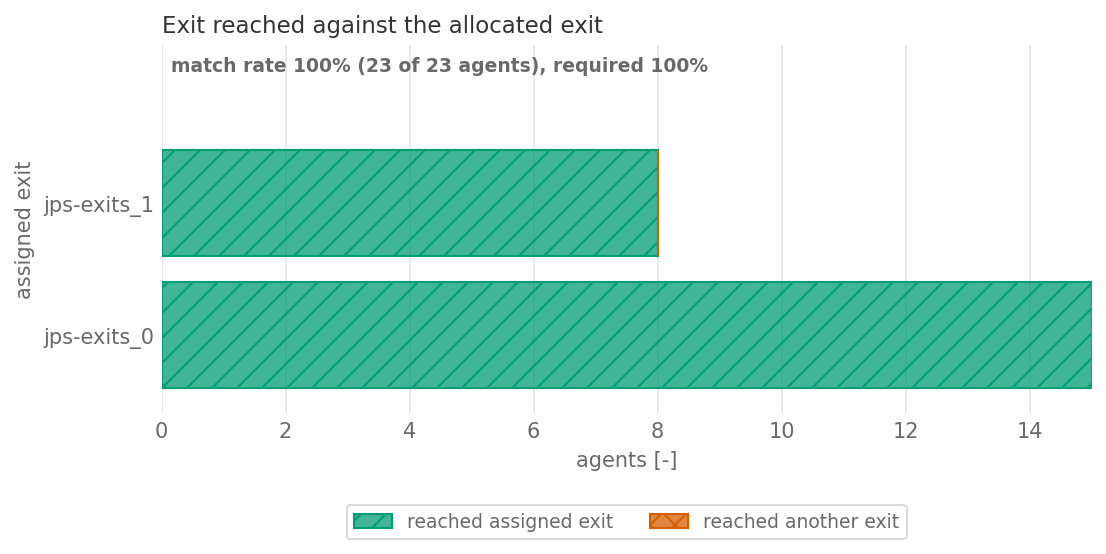

In [11]:
# Agents per assigned exit: how many reached the exit that their route allocates.
tab = pd.DataFrame(assignment_rows).groupby("expected_exit")["matches"].agg(["sum", "count"])
tab["wrong"] = tab["count"] - tab["sum"]
with plt.rc_context(VV_RC):
    fig, ax = plt.subplots(figsize=(8, 1.6 + 0.8 * len(tab)))
    y = np.arange(len(tab))
    ax.barh(y, tab["sum"], color=to_rgba(VV_GREEN, 0.75), edgecolor=VV_GREEN, hatch="//", label="reached assigned exit")
    ax.barh(y, tab["wrong"], left=tab["sum"], color=to_rgba(VV_RED, 0.75), edgecolor=VV_RED, hatch="xx",
            label="reached another exit")
    ax.set_yticks(y, [str(e) for e in tab.index])
    ax.set_ylim(-0.6, len(tab) - 0.5 + 0.7)
    ax.set_xlabel("agents [-]")
    ax.set_ylabel("assigned exit")
    rate = tab["sum"].sum() / tab["count"].sum()
    ax.set_title("Exit reached against the allocated exit", loc="left")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
    ax.text(0.01, 0.97, f"match rate {rate:.0%} ({int(tab['sum'].sum())} of {int(tab['count'].sum())} agents), required 100%",
            transform=ax.transAxes, ha="left", va="top", color="dimgrey", fontweight="semibold", fontsize=9)
    ax.grid(axis="y", visible=False)
    plt.show()

In [12]:
mismatches = [row for row in assignment_rows if not row["matches"]]
print(f"All evacuated: {result.agents_remaining == 0}")
print(f"Mismatches: {len(mismatches)}")
assert result.agents_remaining == 0
assert not mismatches, mismatches

All evacuated: True
Mismatches: 0


In [13]:
result.cleanup()

1